# 08_01 Entropy and Cross-Entropy

**Learning objectives**
- Define **surprise** $-\ln p$, **entropy** $H(p)$ and **cross-entropy** $H(p,q)$, and read them in bits or nats.
- Prove that entropy is largest for the uniform distribution and that $H(p,q)=H(p)+\mathrm{KL}(p\|q)\ge H(p)$.
- Explain why **cross-entropy is the classification loss**: it is the negative log-likelihood of a categorical model, and its gradient with respect to the logits is $q-y$.
- Connect entropy to **coding** (Huffman codes) and to **calibration** (cross-entropy is a proper scoring rule).

**Prerequisites:** [01_01 Bernoulli and Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb), [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb), [07_01 Bayesian updating](../../module_07_bayesian/notebooks/07_01_bayesian_updating_conjugates.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A discrete distribution is a probability vector $p=(p_1,\dots,p_K)$ with $p_k\ge0$ and $\sum_kp_k=1$. The likelihood of independent observations is the product of their probabilities and the log-likelihood is the sum of their logarithms (06_01). Jensen's inequality says that for a concave function such as $\ln$, $E[\ln X]\le\ln E[X]$.

## 3. Intuition and story
A weather station that says "sunny" in the desert tells you almost nothing; a station that says "snow" in the desert is news. **Information is surprise**, and rare events are the surprising ones. **Entropy** is the *average surprise* of a source: a fair coin has 1 bit per flip, a coin that lands heads 99 % of the time has about 0.08 bits per flip, because we rarely learn anything.

Now suppose the true source is $p$ but you build your expectations (or your compression code, or your classifier) from a model $q$. You will be surprised more often than necessary. The average surprise measured with the wrong model is the **cross-entropy** $H(p,q)$, and the extra surprise is the **KL divergence** (next lesson). A classifier trained to minimise cross-entropy is simply a model trained to be as little surprised as possible by the true labels.

## 4. Formal definitions

For a discrete distribution $p$ and a model $q$ on the same outcomes (with $q_k>0$ whenever $p_k>0$):

| Quantity | Definition | Unit |
|---|---|---|
| Surprise of an outcome | $I(x)=-\ln p(x)$ (or $-\log_2p(x)$) | nats (bits) |
| **Entropy** | $H(p)=-\sum_kp_k\ln p_k=E_p[-\ln p(X)]$ | nats; $\div\ln2$ gives bits |
| **Cross-entropy** | $H(p,q)=-\sum_kp_k\ln q_k=E_p[-\ln q(X)]$ | nats |
| **KL divergence** | $\mathrm{KL}(p\|q)=\sum_kp_k\ln\frac{p_k}{q_k}=H(p,q)-H(p)$ | nats |
| **Perplexity** | $\exp\{H(p)\}$ (effective number of equally likely outcomes) | outcomes |
| **Differential entropy** | $h(f)=-\int f(x)\ln f(x)\,dx$ (continuous; can be negative) | nats |

Convention: $0\ln0=0$. For a Bernoulli$(p)$: $H(p)=-p\ln p-(1-p)\ln(1-p)\le\ln2$.

**Classification loss.** For a label $y\in\{1,\dots,K\}$ (one-hot vector $\mathbf y$) and predicted probabilities $q=\mathrm{softmax}(z)$ the per-example **cross-entropy loss** is $-\ln q_y=-\sum_ky_k\ln q_k$; the average over $n$ examples is the empirical cross-entropy $H(\hat p,q)$ between the data and the model.

## 5. Derivations

### 5.1 Why $-\ln p$ is the measure of surprise
Ask that surprise $I(p)$ be (i) decreasing in $p$, (ii) continuous, and (iii) additive for independent events: $I(p_1p_2)=I(p_1)+I(p_2)$. The only such functions are $I(p)=-c\ln p$ for a constant $c>0$; $c=1$ gives nats and $c=1/\ln2$ gives bits. **In plain words.** A certain event ($p=1$) has zero surprise, and two independent events together are exactly as surprising as the sum of their surprises, which forces the logarithm.

### 5.2 Entropy is maximal for the uniform distribution
By Jensen with the concave $\ln$: $H(p)-\ln K=\sum_kp_k\ln\frac1{Kp_k}\le\ln\sum_kp_k\frac1{Kp_k}=\ln1=0$, with equality iff $p_k=1/K$. So $0\le H(p)\le\ln K$: zero for a point mass, $\ln K$ for the uniform. **In plain words.** The most uncertain source is the one where every outcome is equally likely; any lopsidedness makes the next outcome easier to guess.

### 5.3 Cross-entropy is entropy plus KL, and never smaller than entropy
$H(p,q)-H(p)=\sum_kp_k\ln\frac{p_k}{q_k}=-\sum_kp_k\ln\frac{q_k}{p_k}\ge-\ln\sum_kp_k\frac{q_k}{p_k}\ge-\ln1=0$ (Jensen again, Gibbs' inequality). Hence $H(p,q)\ge H(p)$ with equality iff $q=p$. **In plain words.** Using the wrong model can only cost extra surprise, and the best model to use is the truth; this is why minimising cross-entropy drives $q$ towards the true label distribution.

### 5.4 Cross-entropy loss is the negative log-likelihood
For independent labels $y_1,\dots,y_n$ with model probabilities $q(y_i\mid x_i;\theta)$ the log-likelihood is $\sum_i\ln q(y_i\mid x_i)$. Dividing by $-n$ gives the average cross-entropy loss $-\frac1n\sum_i\ln q(y_i\mid x_i)=H(\hat p,q)$, so **minimising cross-entropy = maximising the likelihood** (06_01). For a softmax output $q_k=e^{z_k}/\sum_je^{z_j}$ and the loss $L=-\ln q_y$ the gradient is $\partial L/\partial z_k=q_k-y_k$. **In plain words.** The learning signal for each logit is simply "predicted probability minus truth": push the logit of the true class up in proportion to how unconvinced the model is, and push the others down.

### 5.5 Differential entropy of the normal
For $X\sim N(\mu,\sigma^2)$, $h=E[\tfrac12\ln(2\pi\sigma^2)+\tfrac{(X-\mu)^2}{2\sigma^2}]=\tfrac12\ln(2\pi e\sigma^2)$. Among all densities with variance $\sigma^2$ the normal has the **largest** differential entropy (maximum-entropy property). **In plain words.** If all you know is the mean and variance, the normal is the least committal guess, which is one reason it is the default model for noise.

## 6. Properties and relationships
- **Bounds:** $0\le H(p)\le\ln K$; $H(p,q)\ge H(p)$; $H(p,q)$ is **not symmetric** and is infinite if $q_k=0$ for some $p_k>0$ (a model that rules out something that happens).
- **Chain rule:** $H(X,Y)=H(X)+H(Y\mid X)$, and for independent variables entropies add.
- **Coding:** the shortest possible average code length for symbols from $p$ is between $H(p)$ and $H(p)+1$ bits (Shannon source coding; Huffman codes attain it, Example 2). Using a code built for $q$ costs $H(p,q)$ bits.
- **Proper scoring rule:** the expected log loss is minimised exactly when the reported probabilities equal the true ones, so honest probabilities are optimal (Example 3).
- **Maximum entropy:** uniform on a finite set; exponential on $[0,\infty)$ with a given mean; normal with a given mean and variance.
- **Link to ML and AI:** the logistic and softmax losses, language-model training (perplexity $=e^{\text{cross-entropy}}$), decision-tree splits (entropy and information gain), label smoothing, knowledge distillation (cross-entropy to the teacher's probabilities).

## 7. Helpers

Every quantity is computed from first principles and compared with `scipy`; `log_loss` is the same quantity that `sklearn.metrics.log_loss` computes.

In [2]:
def log_loss(y, P, labels=None):
    # mean negative log probability of the true class; P is (n,) for a binary model or (n, K) for K classes
    y = np.asarray(y); P = np.asarray(P, float)
    if P.ndim == 1: P = np.column_stack([1 - P, P])
    return float(-np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-15, 1))))
def entropy(p, base=np.e):
    p = np.asarray(p, float); m = p > 0
    return -(p[m] * np.log(p[m])).sum() / np.log(base)
def cross_entropy(p, q, base=np.e):
    p = np.asarray(p, float); q = np.asarray(q, float); m = p > 0
    return -(p[m] * np.log(q[m])).sum() / np.log(base)
pp = np.array([0.6, 0.3, 0.1]); qq = np.array([0.5, 0.3, 0.2])
print("entropy:", entropy(pp), "| scipy:", stats.entropy(pp)); print("cross-entropy:", cross_entropy(pp, qq), "| H + KL:", entropy(pp) + stats.entropy(pp, qq))
assert abs(entropy(pp) - stats.entropy(pp)) < 1e-12 and abs(cross_entropy(pp, qq) - (entropy(pp) + stats.entropy(pp, qq))) < 1e-12

entropy: 0.8979457248567797 | scipy: 0.8979457248567798
cross-entropy: 0.9380239408771581 | H + KL: 0.9380239408771581


## 8. 2D visuals

### 8.1 Surprise and the entropy of a coin
Left: the surprise $-\log_2p$ of an outcome with probability $p$. Right: the entropy of a Bernoulli$(p)$ coin in bits, maximal (1 bit) at $p=1/2$.

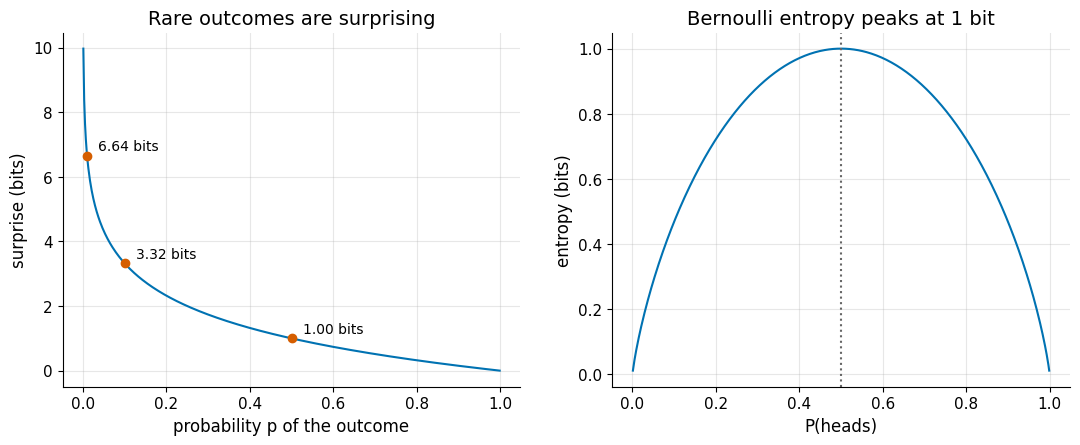

H(0.5) = 1.0 bits | H(0.99) = 0.0808 bits


In [3]:
pg = np.linspace(0.001, 0.999, 500); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(pg, -np.log2(pg), color=MAIN); axes[0].set_xlabel("probability p of the outcome"); axes[0].set_ylabel("surprise (bits)"); axes[0].set_title("Rare outcomes are surprising")
for pt in (0.5, 0.1, 0.01): axes[0].scatter([pt], [-np.log2(pt)], color=HIGHLIGHT, zorder=3); axes[0].annotate(f"{-np.log2(pt):.2f} bits", (pt, -np.log2(pt)), textcoords="offset points", xytext=(8, 4))
hb = -(pg * np.log2(pg) + (1 - pg) * np.log2(1 - pg)); axes[1].plot(pg, hb, color=MAIN); axes[1].axvline(0.5, color=NEUTRAL, linestyle=":"); axes[1].set_xlabel("P(heads)"); axes[1].set_ylabel("entropy (bits)"); axes[1].set_title("Bernoulli entropy peaks at 1 bit")
plt.show(); print("H(0.5) =", entropy([0.5, 0.5], 2), "bits | H(0.99) =", round(entropy([0.99, 0.01], 2), 4), "bits")
assert abs(entropy([0.5, 0.5], 2) - 1) < 1e-12 and abs(entropy([0.99, 0.01], 2) - 0.0808) < 1e-4

### 8.2 Entropy of six distributions on six outcomes
The more evenly spread the probabilities, the higher the entropy; the maximum is $\log_2 6=2.585$ bits.

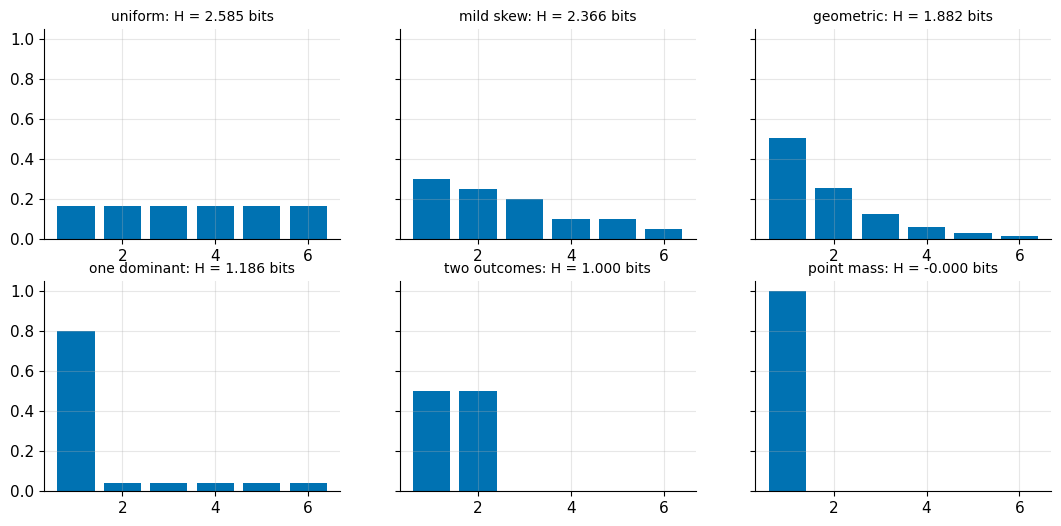

{'uniform': np.float64(2.585), 'mild skew': np.float64(2.366), 'geometric': np.float64(1.882), 'one dominant': np.float64(1.186), 'two outcomes': np.float64(1.0), 'point mass': np.float64(-0.0)}


In [4]:
dists = {"uniform": np.ones(6) / 6, "mild skew": np.array([0.3, 0.25, 0.2, 0.1, 0.1, 0.05]), "geometric": 0.5 ** np.arange(1, 7) / (1 - 0.5 ** 6), "one dominant": np.array([0.8, 0.04, 0.04, 0.04, 0.04, 0.04]), "two outcomes": np.array([0.5, 0.5, 0, 0, 0, 0]), "point mass": np.array([1.0, 0, 0, 0, 0, 0])}
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, (nm, d) in zip(axes.ravel(), dists.items()): ax.bar(range(1, 7), d, color=MAIN); ax.set_title(f"{nm}: H = {entropy(d, 2):.3f} bits", fontsize=10)
plt.show(); H6 = {nm: entropy(d, 2) for nm, d in dists.items()}; print({k: round(v, 3) for k, v in H6.items()})
assert max(H6, key=H6.get) == "uniform" and abs(H6["uniform"] - np.log2(6)) < 1e-12 and H6["point mass"] == 0

### 8.3 Log loss, 0-1 loss and squared error for one example
For a positive example with predicted probability $q$ of the positive class: log loss $-\ln q$, squared (Brier) loss $(1-q)^2$, and 0-1 loss. Log loss punishes confident mistakes without bound.

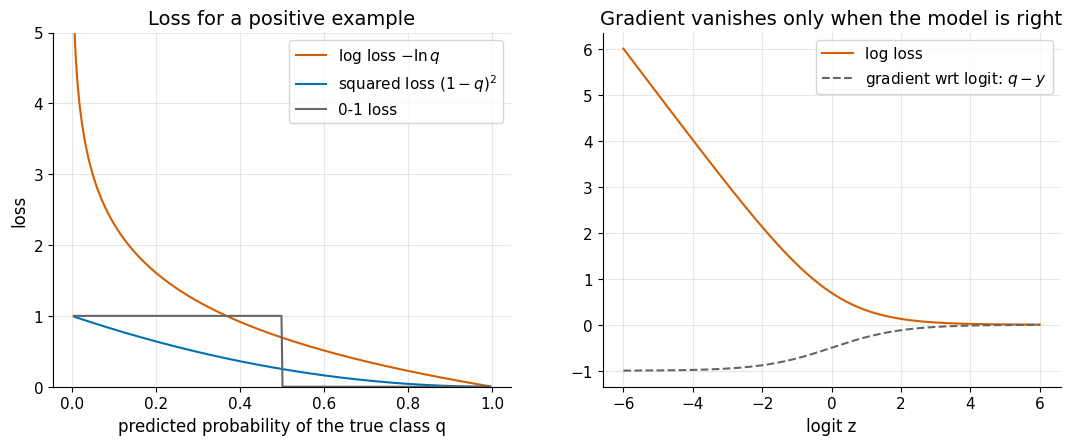

In [5]:
qg = np.linspace(0.005, 0.995, 400); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(qg, -np.log(qg), color=HIGHLIGHT, label="log loss $-\\ln q$"); axes[0].plot(qg, (1 - qg) ** 2, color=MAIN, label="squared loss $(1-q)^2$"); axes[0].plot(qg, (qg < 0.5).astype(float), color=NEUTRAL, label="0-1 loss"); axes[0].set_ylim(0, 5); axes[0].set_xlabel("predicted probability of the true class q"); axes[0].set_ylabel("loss"); axes[0].legend(); axes[0].set_title("Loss for a positive example")
zg = np.linspace(-6, 6, 400); sig = 1 / (1 + np.exp(-zg)); axes[1].plot(zg, -np.log(sig), color=HIGHLIGHT, label="log loss"); axes[1].plot(zg, -(1 - sig), color=NEUTRAL, linestyle="--", label="gradient wrt logit: $q - y$"); axes[1].set_xlabel("logit z"); axes[1].legend(); axes[1].set_title("Gradient vanishes only when the model is right")
plt.show(); assert abs((-np.log(1 / (1 + np.exp(-0.0)))) - np.log(2)) < 1e-12

## 9. 3D visuals

### 9.1 Static: entropy over the probability simplex
For three outcomes the probabilities $(p_1,p_2,1-p_1-p_2)$ live on a triangle. The surface is the entropy in bits; the peak ($\log_23=1.585$) is at the centre, and the surface falls to zero at the three corners.

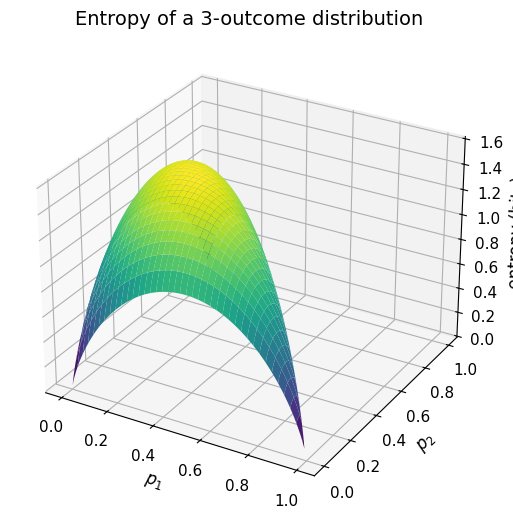

maximum on the grid: 1.5849 bits vs log2(3) = 1.585


In [6]:
a_, b_ = np.meshgrid(np.linspace(0.001, 0.999, 120), np.linspace(0.001, 0.999, 120)); c_ = 1 - a_ - b_; ok = c_ > 0.0005
Hs = np.where(ok, -(a_ * np.log2(a_) + b_ * np.log2(b_) + np.where(ok, c_, 1) * np.log2(np.where(ok, c_, 1))), np.nan)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(a_, b_, Hs, cmap="viridis", edgecolor="none"); ax.set_xlabel("$p_1$"); ax.set_ylabel("$p_2$"); ax.set_zlabel("entropy (bits)"); ax.set_title("Entropy of a 3-outcome distribution"); ax.view_init(elev=28, azim=-60)
plt.show(); print("maximum on the grid:", round(np.nanmax(Hs), 4), "bits vs log2(3) =", round(np.log2(3), 4)); assert abs(np.nanmax(Hs) - np.log2(3)) < 0.01

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=a_, y=b_, z=Hs, colorscale="Viridis")); fig.update_layout(title="Entropy on the simplex (bits)", width=760, height=560, scene=dict(xaxis_title="p1", yaxis_title="p2", zaxis_title="bits")); fig.show()

### 9.3 Static: cross-entropy surface for a fixed truth
With the truth $p=(0.6,0.3,0.1)$ and a model $q=(q_1,q_2,1-q_1-q_2)$ the cross-entropy $H(p,q)$ is a bowl whose lowest point is at $q=p$, where it equals $H(p)$.

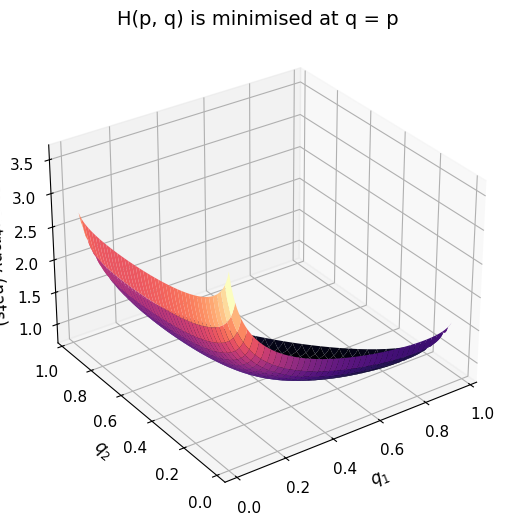

grid minimum at q = 0.605 0.296 | H(p) = 0.8979 nats


In [8]:
q1, q2 = np.meshgrid(np.linspace(0.02, 0.96, 120), np.linspace(0.02, 0.96, 120)); q3 = 1 - q1 - q2; ok = q3 > 0.01
CEs = np.where(ok, -(0.6 * np.log(q1) + 0.3 * np.log(q2) + 0.1 * np.log(np.where(ok, q3, 1))), np.nan); CEs = np.minimum(CEs, 4)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(q1, q2, CEs, cmap="magma", edgecolor="none"); ax.scatter([0.6], [0.3], [entropy(pp)], color="cyan", s=60); ax.set_xlabel("$q_1$"); ax.set_ylabel("$q_2$"); ax.set_zlabel("cross-entropy (nats)"); ax.set_title("H(p, q) is minimised at q = p"); ax.view_init(elev=30, azim=-125)
plt.show(); i_ = np.unravel_index(np.nanargmin(CEs), CEs.shape); print("grid minimum at q =", round(q1[i_], 3), round(q2[i_], 3), "| H(p) =", round(entropy(pp), 4), "nats")
assert abs(q1[i_] - 0.6) < 0.02 and abs(q2[i_] - 0.3) < 0.02 and abs(np.nanmin(CEs) - entropy(pp)) < 0.002

## 10. Simulation vs theory

### 10.1 Average surprise converges to the cross-entropy
Draw labels from $p=(0.6,0.3,0.1)$ and average the surprise $-\ln q(Y)$ under the model $q=(0.5,0.3,0.2)$: the sample average converges to $H(p,q)$ with error $O(1/\sqrt n)$ (law of large numbers, 05_01).

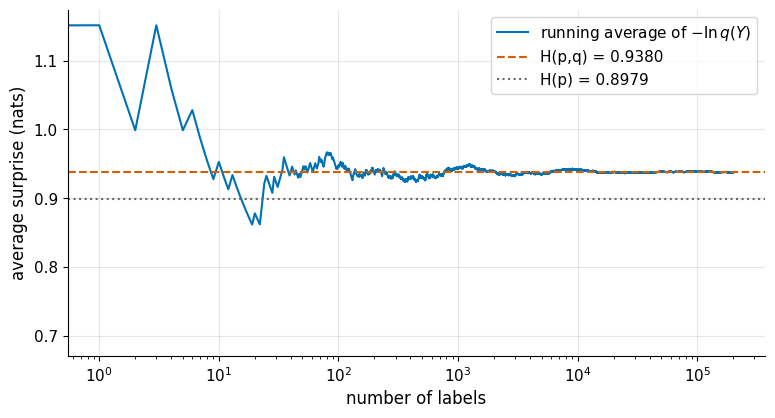

after 200,000 labels: 0.9374 vs H(p,q) = 0.9380


In [9]:
g = np.random.default_rng(1); y = g.choice(3, size=200_000, p=pp); surp = -np.log(qq[y]); run = np.cumsum(surp) / np.arange(1, y.size + 1)
fig, ax = plt.subplots(figsize=(9, 4.5)); ax.plot(run, color=MAIN, label="running average of $-\\ln q(Y)$"); ax.axhline(cross_entropy(pp, qq), color=HIGHLIGHT, linestyle="--", label=f"H(p,q) = {cross_entropy(pp, qq):.4f}"); ax.axhline(entropy(pp), color=NEUTRAL, linestyle=":", label=f"H(p) = {entropy(pp):.4f}"); ax.set_xscale("log"); ax.set_xlabel("number of labels"); ax.set_ylabel("average surprise (nats)"); ax.legend(); plt.show()
print(f"after 200,000 labels: {run[-1]:.4f} vs H(p,q) = {cross_entropy(pp, qq):.4f}"); assert abs(run[-1] - cross_entropy(pp, qq)) < 0.01

### 10.2 The plug-in entropy estimator is biased downwards
Estimating $H$ from $n$ samples by $\hat H=-\sum\hat p_k\ln\hat p_k$ underestimates it by about $(K-1)/(2n)$ nats (Miller-Madow correction). Check by simulation with $K=6$ and $n=20,50,200$.

In [10]:
pk = dists["mild skew"]; Htrue = entropy(pk); g = np.random.default_rng(2); rows = []
for n in (20, 50, 200):
    c = g.multinomial(n, pk, size=40_000) / n; with_log = np.where(c > 0, c * np.log(np.where(c > 0, c, 1)), 0); Hhat = -with_log.sum(axis=1); rows.append((n, Htrue - Hhat.mean(), (len(pk) - 1) / (2 * n), Htrue - (Hhat + (len(pk) - 1) / (2 * n)).mean()))
print(pd.DataFrame(rows, columns=["n", "simulated bias (H - mean H-hat)", "theory (K-1)/(2n)", "bias after Miller-Madow"]).round(4).to_string(index=False))
assert all(abs(r[1] - r[2]) < 0.25 * r[2] for r in rows) and all(abs(r[3]) < abs(r[1]) for r in rows)

  n  simulated bias (H - mean H-hat)  theory (K-1)/(2n)  bias after Miller-Madow
 20                           0.1402             0.1250                   0.0152
 50                           0.0526             0.0500                   0.0026
200                           0.0128             0.0125                   0.0003


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("entropy(p):", stats.entropy(pp), "(nats) |", stats.entropy(pp, base=2), "(bits) | KL(p||q):", stats.entropy(pp, qq))
print("cross-entropy: -(p * np.log(q)).sum() = stats.entropy(p) + stats.entropy(p, q):", -(pp * np.log(qq)).sum())
print("differential entropy:", stats.norm(0, 2).entropy(), "= 0.5 * ln(2 pi e sigma^2) =", 0.5 * np.log(2 * np.pi * np.e * 4), "| expon(scale=3):", stats.expon(scale=3).entropy(), "= 1 + ln 3")
yy = np.array([0, 1, 1, 0]); ph = np.array([0.1, 0.8, 0.6, 0.3]); print("log_loss helper:", log_loss(yy, ph), "| by hand:", -np.mean(yy * np.log(ph) + (1 - yy) * np.log(1 - ph)))
print("softmax gradient: dL/dz = softmax(z) - onehot(y) | perplexity = np.exp(cross_entropy)")
assert abs(log_loss(yy, ph) - (-np.mean(yy * np.log(ph) + (1 - yy) * np.log(1 - ph)))) < 1e-12

entropy(p): 0.8979457248567798 (nats) | 1.295461844238322 (bits) | KL(p||q): 0.04007821602037842
cross-entropy: -(p * np.log(q)).sum() = stats.entropy(p) + stats.entropy(p, q): 0.9380239408771581
differential entropy: 2.112085713764618 = 0.5 * ln(2 pi e sigma^2) = 2.112085713764618 | expon(scale=3): 2.09861228866811 = 1 + ln 3
log_loss helper: 0.2990011586691898 | by hand: 0.2990011586691898
softmax gradient: dL/dz = softmax(z) - onehot(y) | perplexity = np.exp(cross_entropy)


## 12. Real-world worked examples

---
### Example 1 (main): why cross-entropy is the classification loss

**Scenario.** An email service sorts mail into **primary (60 %), promotions (30 %) and spam (10 %)**. Three models give constant forecasts: **A** $(0.5,0.3,0.2)$, an over-confident **B** $(0.8,0.15,0.05)$ and a clueless **C** $(\tfrac13,\tfrac13,\tfrac13)$. We score them on 20,000 emails.

**Questions**
1. What is the entropy of the true label distribution in nats and bits, and what is its perplexity?
2. What is the cross-entropy of each model, and how much of it is the unavoidable $H(p)$ versus the avoidable KL?
3. Check with the average log loss on 20,000 simulated emails (`log_loss`, the helper of section 7).
4. Which model should we deploy, and does accuracy distinguish the models?

### 12.1 By hand
**Q1.** $H=-0.6\ln0.6-0.3\ln0.3-0.1\ln0.1=0.3065+0.3612+0.2303=0.8980$ nats $=1.2955$ bits; perplexity $e^{0.8980}=2.45$ effective classes. **Q2.** $H(p,A)=-(0.6\ln0.5+0.3\ln0.3+0.1\ln0.2)=0.4159+0.3612+0.1609=0.9380$, so KL$=0.0401$; $H(p,B)=0.1339+0.5691+0.2996=1.0026$; $H(p,C)=\ln3=1.0986$ for every $p$. **Q4.** the model with the lowest cross-entropy is closest to the truth: A.

In [12]:
models = {"A (0.5, 0.3, 0.2)": np.array([0.5, 0.3, 0.2]), "B (0.8, 0.15, 0.05)": np.array([0.8, 0.15, 0.05]), "C uniform": np.ones(3) / 3}
g = np.random.default_rng(11); labels = g.choice(3, size=20_000, p=pp)
tab = pd.DataFrame({nm: {"cross-entropy H(p,q)": cross_entropy(pp, q), "KL = H(p,q) - H(p)": cross_entropy(pp, q) - entropy(pp), "log loss on 20,000 emails": log_loss(labels, np.tile(q, (labels.size, 1)), labels=[0, 1, 2]), "accuracy": np.mean(np.argmax(q) == labels), "perplexity": np.exp(cross_entropy(pp, q))} for nm, q in models.items()}).T
print(f"H(p) = {entropy(pp):.4f} nats = {entropy(pp, 2):.4f} bits; perplexity {np.exp(entropy(pp)):.3f}"); print(tab.round(4).to_string())

H(p) = 0.8979 nats = 1.2955 bits; perplexity 2.455
                     cross-entropy H(p,q)  KL = H(p,q) - H(p)  log loss on 20,000 emails  accuracy  perplexity
A (0.5, 0.3, 0.2)                  0.9380              0.0401                     0.9357    0.6022      2.5549
B (0.8, 0.15, 0.05)                1.0026              0.1046                     0.9956    0.6022      2.7253
C uniform                          1.0986              0.2007                     1.0986    0.6022      3.0000


### 12.2 Asserts

In [13]:
assert abs(entropy(pp) - 0.897946) < 1e-5 and abs(entropy(pp, 2) - 1.295462) < 1e-5
assert abs(cross_entropy(pp, models["A (0.5, 0.3, 0.2)"]) - 0.938024) < 1e-5 and abs(cross_entropy(pp, models["B (0.8, 0.15, 0.05)"]) - 1.002595) < 1e-5 and abs(cross_entropy(pp, np.ones(3) / 3) - np.log(3)) < 1e-12
assert all(abs(tab.iloc[i, 0] - tab.iloc[i, 2]) < 0.02 for i in range(3)) and tab["cross-entropy H(p,q)"].idxmin().startswith("A")
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The per-email surprise $-\ln q(y)$ has mean $H(p,q)$ and a computable standard error; check that the simulated mean lies within 3 standard errors for each model.

In [14]:
for nm, q in models.items():
    s_ = -np.log(q[labels]); se = s_.std(ddof=1) / np.sqrt(s_.size); print(f"{nm}: mean surprise {s_.mean():.4f} +/- {se:.4f} | H(p,q) {cross_entropy(pp, q):.4f}"); assert abs(s_.mean() - cross_entropy(pp, q)) <= 3 * se + 1e-9

A (0.5, 0.3, 0.2): mean surprise 0.9357 +/- 0.0022 | H(p,q) 0.9380
B (0.8, 0.15, 0.05): mean surprise 0.9956 +/- 0.0070 | H(p,q) 1.0026
C uniform: mean surprise 1.0986 +/- 0.0000 | H(p,q) 1.0986


### 12.4 Plots

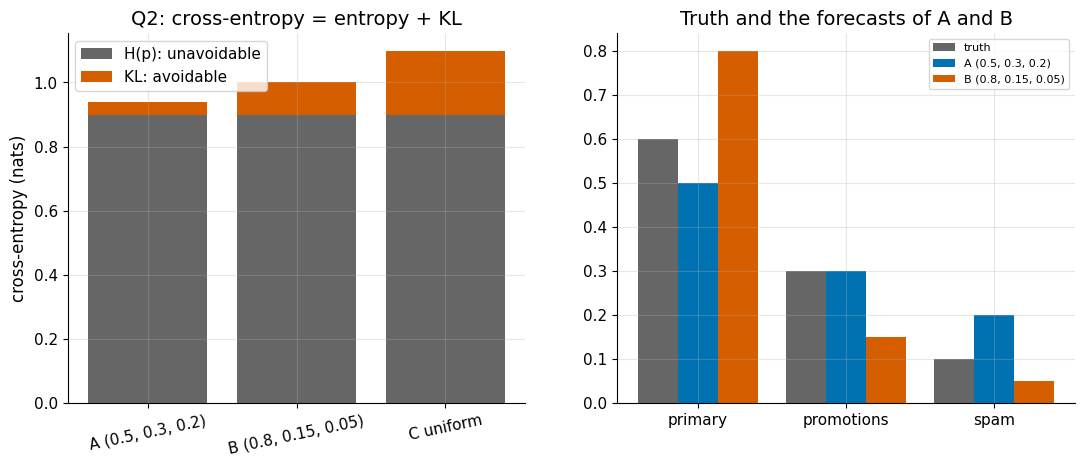

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); nms = list(models); ce_ = [cross_entropy(pp, q) for q in models.values()]
axes[0].bar(nms, [entropy(pp)] * 3, color=NEUTRAL, label="H(p): unavoidable"); axes[0].bar(nms, np.array(ce_) - entropy(pp), bottom=[entropy(pp)] * 3, color=HIGHLIGHT, label="KL: avoidable"); axes[0].set_ylabel("cross-entropy (nats)"); axes[0].legend(); axes[0].set_title("Q2: cross-entropy = entropy + KL"); axes[0].tick_params(axis="x", rotation=12)
x_ = np.arange(3); axes[1].bar(x_ - 0.27, pp, 0.27, color=NEUTRAL, label="truth"); [axes[1].bar(x_ + (i - 0.5) * 0.27 + 0.27 / 2, q, 0.27, color=[MAIN, HIGHLIGHT][i], label=nm) for i, (nm, q) in enumerate(list(models.items())[:2])]; axes[1].set_xticks(x_); axes[1].set_xticklabels(["primary", "promotions", "spam"]); axes[1].legend(fontsize=8); axes[1].set_title("Truth and the forecasts of A and B")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- The true labels have entropy **0.8979 nats = 1.2955 bits**, a perplexity of **2.46**: the mailbox is about as unpredictable as a choice between two and a half equally likely classes. No model can score below 0.8979.
- Cross-entropies: **A 0.9380**, **B 1.0026**, **C 1.0986** ($=\ln3$). The avoidable part is KL $=0.0401,\ 0.1046,\ 0.2007$. The average log loss on the 20,000 simulated emails (0.9357, 0.9956, 1.0986) matches these within the sampling error (0.0022 and 0.0070).
- **Accuracy does not separate the models:** all three have the same arg-max class (primary) and an accuracy of 60.2 %. Only the cross-entropy sees that A's probabilities are closer to the truth than B's over-confident ones, and that B's 5 % for spam (the true rate is 10 %) costs a lot when spam arrives.
- **Decision.** Deploy A, and judge future models against the floor $H(p)=0.898$: a log loss of 0.94 is only 0.04 nats above the best possible, so there is little left to gain from this feature-free forecast.

---
### Example 2: entropy is the length of the best code

**Scenario.** A sensor sends one of five status codes with probabilities $(0.40,0.30,0.15,0.10,0.05)$. A plain fixed-length code needs $\lceil\log_25\rceil=3$ bits per message.

**Questions.** (1) What is the entropy in bits? (2) Build a Huffman code and find its average length; compare with $H$ and $H+1$. (3) What would the average length be if we used the code designed for the uniform distribution $(0.2,\dots,0.2)$, i.e. what is $H(p,q)$ with $q=$ uniform, in bits? (4) Check the average with a simulation of 100,000 messages.

Q1: H = 2.0087 bits | Q2: Huffman lengths [1 2 3 4 4], average 2.050 bits (bounds 2.009 <= L < 3.009) | Q3: H(p, uniform) = 2.3219 bits (= log2 5)
Q4: simulated average length 2.0477 bits per message; the ideal -log2 p averages 2.0068


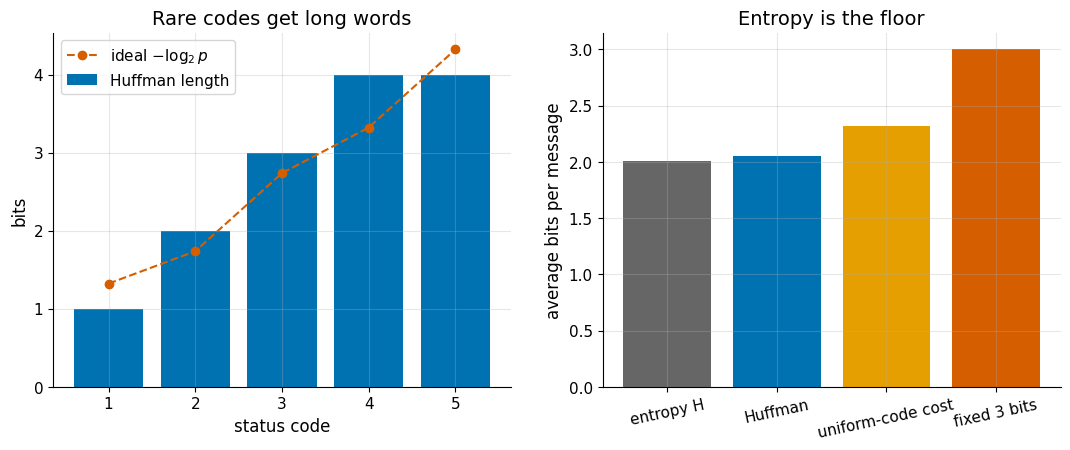

In [16]:
import heapq
def huffman_lengths(p):
    h = [(pi, i, [i]) for i, pi in enumerate(p)]; heapq.heapify(h); depth = np.zeros(len(p), int); cnt = len(p)
    while len(h) > 1:
        a, _, la = heapq.heappop(h); b, _, lb = heapq.heappop(h)
        for i in la + lb: depth[i] += 1
        heapq.heappush(h, (a + b, cnt, la + lb)); cnt += 1
    return depth
p2 = np.array([0.40, 0.30, 0.15, 0.10, 0.05]); L2 = huffman_lengths(p2); avg = (p2 * L2).sum(); q_u = np.ones(5) / 5
print(f"Q1: H = {entropy(p2, 2):.4f} bits | Q2: Huffman lengths {L2}, average {avg:.3f} bits (bounds {entropy(p2, 2):.3f} <= L < {entropy(p2, 2) + 1:.3f}) | Q3: H(p, uniform) = {cross_entropy(p2, q_u, 2):.4f} bits (= log2 5)")
g = np.random.default_rng(12); msgs = g.choice(5, size=100_000, p=p2); print(f"Q4: simulated average length {L2[msgs].mean():.4f} bits per message; the ideal -log2 p averages {(-np.log2(p2[msgs])).mean():.4f}")
assert abs(entropy(p2, 2) - 2.0087) < 1e-3 and abs(avg - 2.05) < 1e-12 and entropy(p2, 2) <= avg < entropy(p2, 2) + 1 and abs(L2[msgs].mean() - avg) < 0.02 and abs(cross_entropy(p2, q_u, 2) - np.log2(5)) < 1e-12
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].bar(range(1, 6), L2, color=MAIN, label="Huffman length"); axes[0].plot(range(1, 6), -np.log2(p2), "o--", color=HIGHLIGHT, label="ideal $-\\log_2 p$"); axes[0].set_xlabel("status code"); axes[0].set_ylabel("bits"); axes[0].legend(); axes[0].set_title("Rare codes get long words")
axes[1].bar(["entropy H", "Huffman", "uniform-code cost", "fixed 3 bits"], [entropy(p2, 2), avg, cross_entropy(p2, q_u, 2), 3], color=[NEUTRAL, MAIN, SIM, HIGHLIGHT]); axes[1].set_ylabel("average bits per message"); axes[1].set_title("Entropy is the floor"); axes[1].tick_params(axis="x", rotation=12)
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The entropy of the status codes is **2.009 bits**. The Huffman code gives the lengths 1, 2, 3, 4, 4 bits and an average of **2.050 bits**, inside the bound $H\le L<H+1$ (2.009 to 3.009). A simulation of 100,000 messages averages 2.048 bits.
- A fixed 3-bit code wastes 0.95 bits per message; the Huffman code saves **31.7 %** of the traffic. A code designed for the uniform distribution would cost $H(p,\text{uniform})=\log_25=$ **2.322 bits**, 0.31 bits above the entropy: the extra bits are the KL divergence of the true distribution from the one the code assumed.
- **Decision.** Use a variable-length code matched to the real frequencies; the entropy tells how much better any code could possibly do (here at most 0.04 bits more than Huffman).

---
### Example 3: confidence versus honesty (cross-entropy is a proper scoring rule)

**Scenario.** A risk model gives the true default probability $\sigma(z_i)$ for 50,000 loans, but we can ship the model with its logits rescaled by a **temperature** $\tau$: predicted probability $\sigma(\tau z_i)$. $\tau=1$ is calibrated, $\tau>1$ over-confident, $\tau<1$ under-confident.

**Questions.** (1) Which $\tau$ minimises the log loss, and how do the log loss, the Brier score and the accuracy change with $\tau$? (2) How large is the loss of the over-confident model at $\tau=3$? (3) Does accuracy detect the problem?

      log loss   Brier  accuracy
tau                             
0.25    0.5723  0.1918    0.7758
0.50    0.5038  0.1643    0.7758
0.75    0.4718  0.1542    0.7758
1.00    0.4635  0.1521    0.7758
1.50    0.4879  0.1564    0.7758
2.00    0.5416  0.1633    0.7758
3.00    0.6872  0.1754    0.7758
5.00    1.0327  0.1902    0.7758
best temperature on the grid: 1.0 | expected log loss of the true probabilities (average entropy) 0.4616


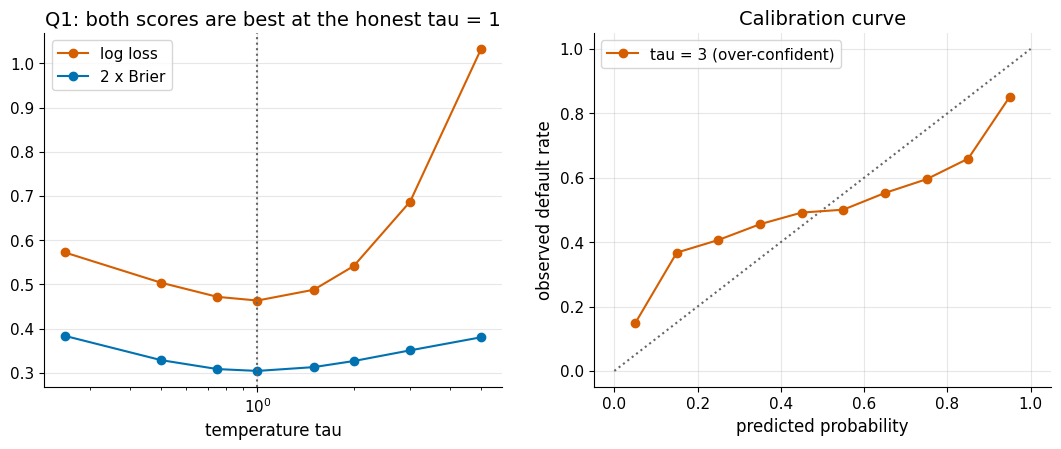

In [17]:
g = np.random.default_rng(13); z = g.normal(0, 2, 50_000); ptrue_ = 1 / (1 + np.exp(-z)); yb = (g.random(z.size) < ptrue_).astype(int)
taus = np.array([0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]); rows = []
for t in taus:
    pr = 1 / (1 + np.exp(-t * z)); rows.append({"tau": t, "log loss": log_loss(yb, pr), "Brier": np.mean((pr - yb) ** 2), "accuracy": np.mean((pr > 0.5) == yb)})
tab3 = pd.DataFrame(rows).set_index("tau"); print(tab3.round(4).to_string()); best_tau = tab3["log loss"].idxmin(); ideal = np.mean(-(ptrue_ * np.log(ptrue_) + (1 - ptrue_) * np.log(1 - ptrue_)))
print(f"best temperature on the grid: {best_tau} | expected log loss of the true probabilities (average entropy) {ideal:.4f}")
assert best_tau == 1.0 and abs(tab3.loc[1.0, "log loss"] - ideal) < 0.01 and tab3["log loss"].is_monotonic_increasing is False
assert tab3.loc[3.0, "log loss"] > tab3.loc[1.0, "log loss"] and abs(tab3.loc[0.25, "accuracy"] - tab3.loc[5.0, "accuracy"]) < 1e-12
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(tab3.index, tab3["log loss"], "o-", color=HIGHLIGHT, label="log loss"); axes[0].plot(tab3.index, tab3["Brier"] * 2, "o-", color=MAIN, label="2 x Brier"); axes[0].axvline(1, color=NEUTRAL, linestyle=":"); axes[0].set_xscale("log"); axes[0].set_xlabel("temperature tau"); axes[0].legend(); axes[0].set_title("Q1: both scores are best at the honest tau = 1")
bins = np.linspace(0, 1, 11); pr3 = 1 / (1 + np.exp(-3 * z)); idx = np.digitize(pr3, bins) - 1; obs = [yb[idx == k].mean() for k in range(10)]; mid = (bins[:-1] + bins[1:]) / 2; axes[1].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[1].plot(mid, obs, "o-", color=HIGHLIGHT, label="tau = 3 (over-confident)"); axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed default rate"); axes[1].legend(); axes[1].set_title("Calibration curve")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The log loss is smallest at the honest temperature **$\tau=1$ (0.4635)**, which is within 0.002 of the average entropy of the true probabilities (0.4616); the Brier score is also smallest at $\tau=1$ (0.1521). Both rise on either side: under-confidence ($\tau=0.25$) gives 0.572, over-confidence ($\tau=3$) gives **0.687 (48 % worse)** and $\tau=5$ gives 1.033.
- **Accuracy is identical (77.6 %) for every $\tau$**, because rescaling the logits never changes which side of 0.5 a probability falls on. Only the log loss and the calibration curve reveal the over-confident model, whose 90 % forecasts come true much less often.
- **Decision.** Always report log loss (or Brier) and a calibration curve next to accuracy, and fit a temperature on a validation set when a model's probabilities are used for decisions such as pricing or approval thresholds.

## 13. Where it is used

### Statistics
- **Maximum likelihood is cross-entropy minimisation** (06_01); entropy defines the **likelihood-ratio and AIC** machinery (KL between model and truth); maximum-entropy distributions justify the normal, exponential and uniform.

### Data science
- **Log loss** as the evaluation metric of probabilistic classifiers (credit scoring, click prediction); **entropy and information gain** for decision trees; **calibration** and temperature scaling; compression and encoding of categorical features.

### ML and AI
- **Softmax classifiers, logistic regression, neural networks and language models** are all trained with cross-entropy; **perplexity** $=e^{\text{cross-entropy}}$ is the standard language-model metric; **label smoothing** and **knowledge distillation** modify the target distribution in the cross-entropy; **RL** uses entropy bonuses to keep policies exploratory.

## 14. Common pitfalls and misconceptions

- **Mixing logarithm bases:** nats ($\ln$) and bits ($\log_2$) differ by the factor $\ln2=0.693$; frameworks report nats, information theory texts bits.
- **Zero probabilities:** $H(p,q)=\infty$ if the model gives probability 0 to something that occurs; clip predictions (e.g. $10^{-15}$) or use label smoothing.
- **Reading cross-entropy as a distance:** it is not symmetric and does not vanish at $q=p$; the distance-like part is KL $=H(p,q)-H(p)$.
- **Comparing losses across tasks:** a log loss of 0.9 is excellent for a 3-class problem with $H(p)=1.1$ but poor for a problem whose entropy is 0.3; compare with the entropy baseline.
- **Trusting accuracy alone:** accuracy ignores confidence (Example 3); check log loss and calibration.
- **Estimating entropy from few samples:** the plug-in estimator is biased low by about $(K-1)/(2n)$ (10.2).
- **Differential entropy is not a count of information:** it can be negative and changes under rescaling of $x$.

## 15. Exercises

1. Compute the entropy in bits of a loaded six-sided die with $P(6)=0.5$ and $P(1)=\dots=P(5)=0.1$.
2. A binary model predicts $q=0.9$ for an email that is spam. What is the surprise in nats and bits, and what is the gradient of the loss with respect to the logit?
3. For the true distribution $(0.7,0.2,0.1)$ and the model $(0.6,0.3,0.1)$ compute $H(p)$, $H(p,q)$ and $\mathrm{KL}(p\|q)$.
4. A language model assigns the probabilities 0.2, 0.05, 0.5 and 0.1 to the four words of a test sentence. Compute the cross-entropy per word and the perplexity.
5. Show numerically that among 4-outcome distributions the uniform one has the largest entropy by checking 100,000 random Dirichlet draws.
6. (Harder) Fit a one-feature logistic regression by gradient descent on simulated data using the gradient $q-y$ and show that the final training log loss equals the `log_loss` helper.

Solutions are at the end.

## 16. Summary table

| Quantity | Formula | Range / meaning |
|---|---|---|
| Surprise | $-\ln p(x)$ | 0 for certainty, large for rare events |
| Entropy $H(p)$ | $-\sum p\ln p$ | $0$ to $\ln K$; average surprise; best code length |
| Cross-entropy $H(p,q)$ | $-\sum p\ln q$ | $\ge H(p)$; classification loss |
| KL | $H(p,q)-H(p)$ | $\ge0$, 0 iff $q=p$ |
| Perplexity | $e^{H}$ | effective number of outcomes |
| Softmax gradient | $q-y$ | prediction minus truth |
| tools | `stats.entropy`, `log_loss` | |

## Solutions

In [18]:
d = np.array([0.1] * 5 + [0.5]); print("1: entropy of the loaded die:", round(entropy(d, 2), 4), "bits (fair die:", round(np.log2(6), 4), ")")
print(f"2: surprise {-np.log(0.9):.4f} nats = {-np.log2(0.9):.4f} bits; gradient q - y = {0.9 - 1:.1f} (for the spam logit; the model is nearly right so the push is small)")
p3 = np.array([0.7, 0.2, 0.1]); q3 = np.array([0.6, 0.3, 0.1]); print(f"3: H(p) = {entropy(p3):.4f}, H(p,q) = {cross_entropy(p3, q3):.4f}, KL = {cross_entropy(p3, q3) - entropy(p3):.4f}")
ce4 = -np.mean(np.log([0.2, 0.05, 0.5, 0.1])); print(f"4: cross-entropy per word {ce4:.4f} nats, perplexity {np.exp(ce4):.3f}")
D = np.random.default_rng(14).dirichlet(np.ones(4), size=100_000); Hd = -(D * np.log(D)).sum(axis=1); print(f"5: maximum entropy over 100,000 Dirichlet draws {Hd.max():.4f} < ln 4 = {np.log(4):.4f}")
g = np.random.default_rng(15); x = g.normal(size=2000); yv = (g.random(2000) < 1 / (1 + np.exp(-(0.5 + 1.5 * x)))).astype(int); w = np.zeros(2)
for _ in range(3000):
    qh = 1 / (1 + np.exp(-(w[0] + w[1] * x))); w -= 0.5 * np.array([np.mean(qh - yv), np.mean((qh - yv) * x)])
qh = 1 / (1 + np.exp(-(w[0] + w[1] * x))); print(f"6: gradient descent weights {np.round(w, 3)}, final loss {-np.mean(yv * np.log(qh) + (1 - yv) * np.log(1 - qh)):.5f} vs the log_loss helper {log_loss(yv, qh):.5f}")
assert abs(entropy(d, 2) - 2.1610) < 1e-3 and np.log2(6) > entropy(d, 2) and Hd.max() < np.log(4) and abs(-np.mean(yv * np.log(qh) + (1 - yv) * np.log(1 - qh)) - log_loss(yv, qh)) < 1e-9

1: entropy of the loaded die: 2.161 bits (fair die: 2.585 )
2: surprise 0.1054 nats = 0.1520 bits; gradient q - y = -0.1 (for the spam logit; the model is nearly right so the push is small)
3: H(p) = 0.8018, H(p,q) = 0.8286, KL = 0.0268
4: cross-entropy per word 1.9002 nats, perplexity 6.687
5: maximum entropy over 100,000 Dirichlet draws 1.3861 < ln 4 = 1.3863
6: gradient descent weights [0.509 1.481], final loss 0.51573 vs the log_loss helper 0.51573


**1.** $H=-5(0.1\log_20.1)-0.5\log_20.5=1.661+0.5=$ **2.161 bits**, below the fair die's 2.585 bits.

**2.** Surprise $-\ln0.9=$ **0.105 nats** $=0.152$ bits; the gradient with respect to the spam logit is $q-y=0.9-1=$ **-0.1** (the loss falls when the logit rises, gently because the model is nearly right).

**3.** $H(p)=$ **0.8018**, $H(p,q)=$ **0.8286**, KL $=$ **0.0268** nats.

**4.** The cross-entropy per word is **1.900 nats**, a perplexity of **6.69**: the model is as uncertain as a uniform choice among about 6.7 words.

**5.** The largest entropy among 100,000 Dirichlet draws is **1.3861**, just below $\ln4=1.3863$, never above.

**6.** Gradient descent with the gradient $q-y$ gives the weights **0.509 and 1.481** (true 0.5 and 1.5) and a final loss of **0.51573**, equal to the `log_loss` helper (0.51573).